# 02 · Pré-processamento e feature engineering
**Tech Challenge – Fase 2 · Grupo 01 · POSTECH Data Analytics**

Aqui transformamos os dados brutos em uma base pronta para o modelo, seguindo o que o notebook 01 mostrou:
construir o alvo, tratar nulos e outliers, criar variáveis mais informativas e padronizar as escalas.
O resultado é salvo em `data/processed/dataset_model.csv` (pasta não versionada).

In [1]:
RANDOM_STATE = 42   # semente fixa

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RAW, PROCESSED = "../data/raw/", "../data/processed/"
app = pd.read_csv(RAW + "application_record.csv"); cred = pd.read_csv(RAW + "credit_record.csv")

## 1. Decisões de limpeza

| Problema (visto no notebook 01) | O que fizemos | Por quê |
|---|---|---|
| Sem coluna de bom/mau | `TARGET = 1` se houve atraso ≥ 30 dias em algum mês | Gera o rótulo a partir do histórico real |
| Clientes sem histórico | Mantemos só quem está nas duas tabelas | Sem histórico não há "resposta" |
| 47 IDs duplicados | Mantemos o primeiro registro | Evita contar a mesma pessoa duas vezes |
| `DAYS_BIRTH` e `DAYS_EMPLOYED` em dias negativos | Convertemos para **anos** (`AGE_YEARS`, `YEARS_EMPLOYED`) | Leitura direta e útil |
| Código 365243 em `DAYS_EMPLOYED` | Vira o indicador `IS_UNEMPLOYED_OR_RETIRED` e `YEARS_EMPLOYED = 0` | Não é um tempo de emprego real |
| `OCCUPATION_TYPE` nulo (30,6%) | Categoria própria **"Nao informado"** | O nulo carrega informação (aposentados etc.), e apagar perderia 30% dos clientes |
| Renda com cauda muito longa | `LOG_INCOME` (logaritmo) | Reduz o peso de rendas extremas |
| Filhos e família com extremos | Limitamos: filhos ≤ 5, família ≤ 7 | Mantém o cliente, tira o exagero |
| `FLAG_MOBIL` constante | Removida | Não separa ninguém |
| Textos Y/N e M/F | Convertidos em 0/1 | Os modelos precisam de números |

In [2]:
def build_target(cred, threshold=1):
    bad_values = [str(s) for s in range(threshold, 6)]
    return cred["STATUS"].isin(bad_values).groupby(cred["ID"]).max().astype(int).rename("TARGET")

def clean_and_engineer(app, target):
    df = app.drop_duplicates("ID").merge(target, left_on="ID", right_index=True, how="inner")

    # idade e tempo de emprego em anos; 365243 = sem emprego/aposentado
    df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
    df["IS_UNEMPLOYED_OR_RETIRED"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
    df["YEARS_EMPLOYED"] = np.where(df["DAYS_EMPLOYED"] == 365243, 0, -df["DAYS_EMPLOYED"] / 365.25)

    # nulos: ocupação ausente vira categoria própria
    df["OCCUPATION_TYPE"] = df["OCCUPATION_TYPE"].fillna("Nao informado")

    # variáveis derivadas
    df["LOG_INCOME"] = np.log1p(df["AMT_INCOME_TOTAL"])
    df["LOG_INCOME_PER_MEMBER"] = np.log1p(df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"].clip(lower=1))

    # outliers: limitar caudas
    df["CNT_CHILDREN"] = df["CNT_CHILDREN"].clip(upper=5)
    df["CNT_FAM_MEMBERS"] = df["CNT_FAM_MEMBERS"].clip(upper=7)

    # binárias
    for col in ["FLAG_OWN_CAR", "FLAG_OWN_REALTY"]:
        df[col] = (df[col] == "Y").astype(int)
    df["IS_MALE"] = (df["CODE_GENDER"] == "M").astype(int)

    df = df.drop(columns=["FLAG_MOBIL", "CODE_GENDER", "DAYS_BIRTH", "DAYS_EMPLOYED"])

    # identificador do perfil (mesmas características) para dividir treino/teste sem vazamento
    feat_cols = [c for c in df.columns if c not in ("ID", "TARGET")]
    df["PROFILE_GROUP"] = (pd.util.hash_pandas_object(df[feat_cols], index=False) % (2**31)).astype("int64")
    return df.reset_index(drop=True)

df = clean_and_engineer(app, build_target(cred, 1))
print("Antes (cadastro bruto):", app.shape, "| Depois (base de modelagem):", df.shape)
print(f"% de maus pagadores: {df.TARGET.mean():.2%} | perfis únicos: {df.PROFILE_GROUP.nunique():,}".replace(",", "."))
print("Nulos restantes:", int(df.isna().sum().sum()))
display(df.head(3))

Antes (cadastro bruto): (438557, 18) | Depois (base de modelagem): (36457, 22)
% de maus pagadores: 11.77% | perfis únicos: 9.727
Nulos restantes: 0


,ID,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET,AGE_YEARS,IS_UNEMPLOYED_OR_RETIRED,YEARS_EMPLOYED,LOG_INCOME,LOG_INCOME_PER_MEMBER,IS_MALE,PROFILE_GROUP
0,5008804,1,1,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,1,0,0,Nao informado,2.0,1,32.867899,0,12.435318,12.965712,12.272567,1,1812438062
1,5008805,1,1,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,1,0,0,Nao informado,2.0,1,32.867899,0,12.435318,12.965712,12.272567,1,1812438062
2,5008806,1,1,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,0,0,0,Security staff,2.0,0,58.792608,0,3.104723,11.630717,10.937579,1,1691258111


**Leitura:** a base passou de 438 mil linhas e 18 colunas para **36.457 clientes** e 22 colunas, sem nenhum nulo, com 11,77% de maus pagadores.

## 2. Efeito do tratamento de outliers e da renda

Assimetria da renda: 2.7 (original) -> 0.1 (log)


,antes (cadastro bruto),depois do tratamento
filhos (máximo),19.0,5.0
pessoas na família (máximo),20.0,7.0


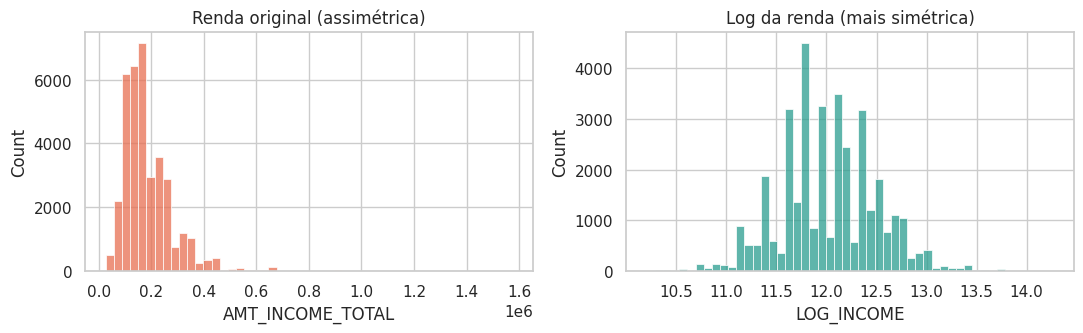

In [3]:
mm = pd.DataFrame({"antes (cadastro bruto)": [app.CNT_CHILDREN.max(), app.CNT_FAM_MEMBERS.max()],
                   "depois do tratamento": [df.CNT_CHILDREN.max(), df.CNT_FAM_MEMBERS.max()]}, index=["filhos (máximo)", "pessoas na família (máximo)"])
display(mm)
print(f"Assimetria da renda: {df.AMT_INCOME_TOTAL.skew():.1f} (original) -> {df.LOG_INCOME.skew():.1f} (log)")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df.AMT_INCOME_TOTAL, bins=50, ax=axes[0], color="#e76f51"); axes[0].set_title("Renda original (assimétrica)")
sns.histplot(df.LOG_INCOME, bins=50, ax=axes[1], color="#2a9d8f"); axes[1].set_title("Log da renda (mais simétrica)")
plt.tight_layout(); plt.show()

**Leitura:** a renda original tem a maior parte dos clientes à esquerda e uma cauda longa à direita. Depois do logaritmo, a distribuição fica mais equilibrada (a assimetria cai de 2,7 para 0,1),
o que ajuda principalmente a regressão logística. Filhos e tamanho da família agora têm teto razoável.

## 3. Features criadas

| Variável | Para que serve |
|---|---|
| `AGE_YEARS`, `YEARS_EMPLOYED` | Idade e tempo de emprego em anos |
| `IS_UNEMPLOYED_OR_RETIRED` | Marca quem não trabalha (aposentados/desempregados) |
| `LOG_INCOME` | Renda em escala logarítmica |
| `LOG_INCOME_PER_MEMBER` | Renda por pessoa da família: 100 mil para 1 pessoa é diferente de 100 mil para 5 |
| `OCCUPATION_TYPE = "Nao informado"` | Mantém o grupo sem ocupação como categoria própria |
| `IS_MALE` | Gênero em 0/1 |
| `PROFILE_GROUP` | Identifica perfis idênticos; **não entra no modelo**, só serve para dividir treino e teste sem vazamento |

## 4. Normalização (padronização de escala)
As variáveis numéricas têm escalas muito diferentes (idade ~40, renda em log ~12, filhos ~0,4). Aplicamos **StandardScaler** (média 0, desvio 1) porque:
- a **Regressão Logística** é sensível à escala: sem padronizar, variáveis de números grandes dominariam o ajuste;
- as árvores (Árvore, Random Forest, Gradient Boosting) **não precisam**, mas a padronização não as prejudica e permite usar o mesmo pré-processamento para todos os modelos.

As variáveis de texto (ocupação, escolaridade etc.) recebem **one-hot encoding** (uma coluna 0/1 por categoria).
**Importante:** o scaler é ajustado **somente com dados de treino**, dentro do `Pipeline` do notebook 03, para que nada do teste "vaze" para o treino. Abaixo, apenas a demonstração do efeito:

In [4]:
NUMERIC = ["CNT_CHILDREN", "CNT_FAM_MEMBERS", "AGE_YEARS", "YEARS_EMPLOYED", "LOG_INCOME", "LOG_INCOME_PER_MEMBER"]
antes = df[NUMERIC].agg(["mean", "std"]).T.round(2)
depois = pd.DataFrame(StandardScaler().fit_transform(df[NUMERIC]), columns=NUMERIC).agg(["mean", "std"]).T.round(2)
display(pd.concat({"antes": antes, "depois da padronização": depois}, axis=1))

**Leitura:** antes, as médias iam de 0,4 a 43; depois, todas as variáveis ficam com média 0 e desvio 1, em pé de igualdade para o modelo.

## 5. Salvar a base tratada

In [5]:
df.to_csv(PROCESSED + "dataset_model.csv", index=False)
print("Salvo em data/processed/dataset_model.csv:", df.shape)

Salvo em data/processed/dataset_model.csv: (36457, 22)
